<div dir="rtl" style="text-align: right; direction: rtl; line-height: 1.7; font-family: 'Segoe UI', Arial, sans-serif;">

# ניתוח נתוני כליאה חודשיים – שנת 2024
### מטלת הערכה לתפקיד אנליסט/ית מחקר – חטיבת התכנון, שירות בתי הסוהר
**מגישה:** נועה בוחניק - 322634106  
**בסיס הנתונים:** ארבעת הדוחות הרבעוניים לשנת 2024 (12 חודשים מלאים – גיליונות פלילי וביטחוני)

---
### רקע ותמצית מנהלים:
במסגרת עבודה זו נותחו דוחות הכליאה החודשיים של שירות בתי הסוהר לאורך שנת 2024 (12 חודשים מלאים), תוך בחינת המגמות המרכזיות באוכלוסייה הפלילית (גיליון 4) ובאוכלוסייה הביטחונית (גיליון 3), במטרה לגבש תמונת מצב עדכנית ולהפיק המלצות יישומיות לתכנון המערך.

**עיקרי הממצאים שעלו מן הניתוח:**

1. **האוכלוסייה הפלילית ומאפייני שהייה בלתי חוקית (שב"ח):** לאורך השנה נרשמה עלייה עקבית של **24.0%** במצבת הכלואים הפליליים (מ-2,250 כלואים בינואר ל-2,790 בדצמבר, עם שיא שנתי של 2,994 בנובמבר). עיקר הגידול (**94.6%**) נבע מזינוק בעבירות שב"ח (עלייה של **46.3%**), כתוצאה מהגברת פעילות האכיפה וסגירת המעברים בעקבות מלחמת חרבות ברזל. תושבי איו"ש מהווים **81.4%** מכלל הכלואים הפליליים, כאשר הרוב המכריע מוחזקים בגין עבירות כניסה ושהייה שלא כדין.
2. **דפוסי כליאת קטינים (16–18) והשפעת חופשת הקיץ:** במהלך חודשי הקיץ נרשמה עלייה חדה במספר הקטינים הכלואים, שהגיעה לשיא בחודש אוגוסט (**132 קטינים**, עלייה של **33.3%** לעומת חודש מאי). לצד העונתיות, נמצא כי אוכלוסיית הקטינים מתאפיינת בשיעור עצורים גבוה במיוחד (**71.1% עצורים עד תום ההליכים**, לעומת 42.3% בלבד בקרב בגירים).
3. **פילוח מגדרי:** נשים מהוות כ-**0.6%** בלבד מהאוכלוסייה הפלילית (ממוצע חודשי של 17 כלואות). מרביתן המכריע תושבות איו"ש (**85.3%**) אשר נכלאו בגין עבירות שב"ח (**60.3%**).
4. **האוכלוסייה הביטחונית והשפעות הלחימה:** המצבה הביטחונית צמחה ב-**17.4%** (מ-8,602 כלואים ל-10,097). במהלך חודש יולי (מבצע רפיח) עקף חמאס לראשונה את פת"ח במספר הכלואים, כאשר חמאס מחזיק בלמעלה מ-**90%** מכלל הלוחמים הבלתי חוקיים (שמספרם עלה פי 3.1, מ-604 ל-1,889). במקביל, זוהתה עלייה חדה של **127.1%** בכלואים ללא שיוך ארגוני מוגדר (מפגעים בודדים).
</div>

<div dir="rtl" style="text-align: right; direction: rtl; line-height: 1.6; font-family: 'Segoe UI', Arial, sans-serif;">

### שלב 1: טעינת ספריות, הגדרות תצוגה ועיבוד עברית (RTL)
</div>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
from IPython.display import display, HTML
from bidi.algorithm import get_display

warnings.filterwarnings('ignore')

# הגדרות תצוגה
%matplotlib inline
pd.set_option('display.max_columns', 25)
pd.set_option('display.width', 1000)
plt.rcParams['figure.figsize'] = (16, 11)
plt.rcParams['font.size'] = 11

def rtl(text):
    if not isinstance(text, str):
        return text
    return get_display(text)

def show_rtl_table(df_table, title=""):
    html = f'''<div dir="rtl" style="text-align: right; direction: rtl; unicode-bidi: embed; font-family: 'Segoe UI', Arial, sans-serif; margin: 16px 0; background-color: #ffffff; padding: 14px; border-radius: 8px; box-shadow: 0 3px 8px rgba(0,0,0,0.1); border: 1.5px solid #cbd5e1;">
    <div style="font-size: 15px; font-weight: 700; color: #1e3a8a; border-bottom: 2px solid #2563eb; padding-bottom: 6px; margin-bottom: 10px; text-align: right;">{title}</div>
    <table style="direction: rtl; text-align: right; width: 100%; border-collapse: collapse; font-size: 13px; background-color: #ffffff; color: #000000;">
        <thead>
            <tr style="background-color: #0f172a; color: #ffffff;">
'''
    for col in df_table.columns:
        html += f'                <th style="padding: 10px 12px; text-align: right; border: 1px solid #334155; font-weight: 700; color: #ffffff !important; background-color: #0f172a; font-size: 13px;">{col}</th>\n'
    html += '            </tr>\n        </thead>\n        <tbody>\n'
    for i, row in df_table.iterrows():
        bg = '#f1f5f9' if i % 2 == 0 else '#ffffff'
        html += f'            <tr style="background-color: {bg};">\n'
        for val in row:
            html += f'                <td style="padding: 8px 12px; text-align: right; border: 1px solid #cbd5e1; color: #000000 !important; font-weight: 600; font-size: 12.5px; background-color: {bg};">{val}</td>\n'
        html += '            </tr>\n'
    html += '''        </tbody>
    </table>
</div>'''
    display(HTML(html))

month_names = ['ינואר', 'פברואר', 'מרץ', 'אפריל', 'מאי', 'יוני', 'יולי', 'אוגוסט', 'ספטמבר', 'אוקטובר', 'נובמבר', 'דצמבר']
chronological_months = [f"{m} 2024" for m in month_names]

file_map = {
    'רבעון 1': 'דוח כלואים רבעון 1 לשנת 2024.xlsx',
    'רבעון 2': 'אפריל 2024 דוח כלואים - רבעון שני שנת אפריל 2024.xlsx',
    'רבעון 3': 'דוח כלואים -רבעון שלישי לשנת יולי 2024.xlsx',
    'רבעון 4': '2024אוקטובר דוח כלואים- רבעון רביעי לשנת 2024אוקטובר.xlsx'
}


<div dir="rtl" style="text-align: right; direction: rtl; line-height: 1.7; font-family: 'Segoe UI', Arial, sans-serif;">

---
# פרק א': ניתוח אוכלוסיית הכלואים הפליליים (גיליון 4)

### אבני דרך מרכזיות וניתוח כרונולוגי לאורך שנת 2024:
1. **ינואר (2,250 כלואים):** רמת הבסיס השנתית. משקפת את תחילת העלייה בעקבות סגירת המעברים והקשחת מדיניות האכיפה כלפי שוהים בלתי חוקיים לאחר אירועי 7 באוקטובר.
2. **מרץ (2,484 כלואים / עלייה של 10.4%):** תקופת חודש הרמדאן, המאופיינת בפעילות סיכול מוגברת ביהודה ושומרון ובמעצרי מנע.
3. **אוגוסט (2,950 כלואים):** השפעה משולבת של פגרת בתי המשפט (שהביאה לשיא שנתי של 1,418 עצורים) יחד עם חופשת הקיץ של מערכת החינוך (שיא שנתי של 132 קטינים).
4. **נובמבר (2,994 כלואים / עלייה מצטברת של 33.1%):** שיא הכליאה השנתי, בעקבות מבצעי אכיפה רחבים לאחר חגי תשרי והיערכות החורף.
5. **דצמבר (2,790 כלואים / עלייה שנתית נטו של 24.0%):** ירידה קלה בסוף השנה האזרחית עקב סיום תקופות מאסר קצרות ושחרור שפוטים.
</div>

In [2]:
records_crim = []

for q_name, file in file_map.items():
    df_raw = pd.read_excel(file, sheet_name=3, header=None)
    current_month = None
    current_residence = None
    current_gender = None
    
    for row_idx in range(len(df_raw)):
        row = df_raw.iloc[row_idx].tolist()
        for cell in row:
            if pd.notna(cell):
                cell_s = str(cell).strip()
                for m in month_names:
                    if m in cell_s and '2024' in cell_s:
                        current_month = f"{m} 2024"
                        break
                        
        c3 = str(row[3]).strip() if len(row) > 3 and pd.notna(row[3]) else ''
        if any(x in c3 for x in ["יו'ש", 'יו"ש', 'איוש']):
            current_residence = "יו'ש"
        elif any(x in c3 for x in ['מזרח ירושלים', 'מזרח י-ם']):
            current_residence = "מזרח י-ם"
        elif any(x in c3 for x in ["אזח'ע", 'אזח"ע', 'עזה']):
            current_residence = "אזח'ע"
        elif 'ישראל' in c3:
            current_residence = "ישראל"
        elif 'זרים' in c3:
            current_residence = "זרים"
            
        c4 = str(row[4]).strip() if len(row) > 4 and pd.notna(row[4]) else ''
        if 'גברים' in c4:
            current_gender = 'גברים'
        elif 'נשים' in c4:
            current_gender = 'נשים'
            
        c5 = str(row[5]).strip() if len(row) > 5 and pd.notna(row[5]) else ''
        if c5 and c5 not in ['סוג עבירה ראשית ', 'סוג עבירה ראשית', 'nan', 'סה"כ'] and not any(x in c5 for x in ['פלילי', 'בגירים', '18-16']):
            v7 = pd.to_numeric(row[7], errors='coerce') if len(row) > 7 else 0
            v8 = pd.to_numeric(row[8], errors='coerce') if len(row) > 8 else 0
            v9 = pd.to_numeric(row[9], errors='coerce') if len(row) > 9 else 0
            v10 = pd.to_numeric(row[10], errors='coerce') if len(row) > 10 else 0
            
            n7 = int(v7) if pd.notna(v7) else 0
            n8 = int(v8) if pd.notna(v8) else 0
            n9 = int(v9) if pd.notna(v9) else 0
            n10 = int(v10) if pd.notna(v10) else 0
            total = n7 + n8 + n9 + n10
            
            if total > 0 and current_month and current_residence:
                records_crim.append({
                    'רבעון': q_name,
                    'חודש': current_month,
                    'תושבות': current_residence,
                    'מגדר': current_gender if current_gender else 'גברים',
                    'עבירה': c5,
                    'קטינים_עצורים': n7,
                    'קטינים_שפוטים': n8,
                    'בגירים_עצורים': n9,
                    'בגירים_שפוטים': n10,
                    'קטינים': n7 + n8,
                    'בגירים': n9 + n10,
                    'עצורים': n7 + n9,
                    'שפוטים': n8 + n10,
                    'סה"כ כלואים': total
                })

df_crim = pd.DataFrame(records_crim)
df_crim['מספר חודש'] = df_crim['חודש'].apply(lambda x: month_names.index(x.split()[0]) + 1)
df_crim = df_crim.sort_values('מספר חודש').reset_index(drop=True)
print(f"✓ נטענו בהצלחה {len(df_crim):,} רשומות פליליות ב-12 החודשים של 2024.")


✓ נטענו בהצלחה 452 רשומות פליליות ב-12 החודשים של 2024.


<div dir="rtl" style="text-align: right; direction: rtl; line-height: 1.6; font-family: 'Segoe UI', Arial, sans-serif;">

### טבלאות נתונים: התפתחות חודשית, עבירות מובילות, פילוח גיאוגרפי, גיל ומגדר
</div>

In [3]:
# 1. התפתחות חודשית כללית
monthly_crim = df_crim.groupby(['מספר חודש', 'חודש'])['סה"כ כלואים'].sum().reset_index()
jan_crim = monthly_crim.iloc[0]['סה"כ כלואים']
monthly_crim['שינוי מצטבר (%)'] = ((monthly_crim['סה"כ כלואים'] - jan_crim) / jan_crim * 100).round(1)
monthly_crim['שינוי חודשי (%)'] = (monthly_crim['סה"כ כלואים'].pct_change() * 100).round(1).fillna(0.0)

t1_styled = pd.DataFrame({
    'חודש': monthly_crim['חודש'],
    'מצבת כלואים': monthly_crim['סה"כ כלואים'].apply(lambda x: f"{x:,}"),
    'שינוי חודשי': monthly_crim['שינוי חודשי (%)'].apply(lambda x: f"{x:+.1f}%"),
    'שינוי מצטבר מינואר': monthly_crim['שינוי מצטבר (%)'].apply(lambda x: f"{x:+.1f}%")
})
show_rtl_table(t1_styled, "טבלה 1: התפתחות מצבת הכלואים הפליליים לאורך שנת 2024")

# 2. חמש העבירות המובילות
off_ann = df_crim.groupby('עבירה')['סה"כ כלואים'].sum().sort_values(ascending=False).reset_index()
off_ann['אחוז מסך העבירות'] = (off_ann['סה"כ כלואים'] / off_ann['סה"כ כלואים'].sum() * 100).round(1)

t2_styled = pd.DataFrame({
    'סוג עבירה': off_ann.head(6)['עבירה'],
    'סך כלואים מצטבר': off_ann.head(6)['סה"כ כלואים'].apply(lambda x: f"{x:,}"),
    'אחוז מסך הכל': off_ann.head(6)['אחוז מסך העבירות'].astype(str) + '%'
})
show_rtl_table(t2_styled, "טבלה 2: התפלגות שנתית של עבירות פליליות מובילות")

# 3. פילוח גיאוגרפי
res_table = df_crim.groupby('תושבות')['סה"כ כלואים'].sum().sort_values(ascending=False).reset_index()
res_table['אחוז מסך הכל'] = (res_table['סה"כ כלואים'] / res_table['סה"כ כלואים'].sum() * 100).round(1)

t3_styled = pd.DataFrame({
    'אזור תושבות': res_table['תושבות'].replace({"יו'ש": 'איו"ש (יהודה ושומרון)', "מזרח י-ם": 'מזרח ירושלים', "אזח'ע": 'רצועת עזה'}),
    'סך כלואים מצטבר': res_table['סה"כ כלואים'].apply(lambda x: f"{x:,}"),
    'אחוז מסך הכל': res_table['אחוז מסך הכל'].astype(str) + '%'
})
show_rtl_table(t3_styled, "טבלה 3: התפלגות גיאוגרפית שנתית של הכלואים הפליליים")

# 4. פילוח גילאי מלא ועונתיות החופש הגדול (קטינים מול בגירים)
age_monthly = df_crim.groupby('חודש')[['קטינים', 'קטינים_עצורים', 'קטינים_שפוטים', 'בגירים', 'בגירים_עצורים', 'בגירים_שפוטים', 'סה"כ כלואים']].sum().reindex(chronological_months).reset_index()
age_monthly['אחוז קטינים'] = (age_monthly['קטינים'] / age_monthly['סה"כ כלואים'] * 100).round(1).astype(str) + '%'
age_monthly['אחוז עצורים בקטינים'] = (age_monthly['קטינים_עצורים'] / age_monthly['קטינים'] * 100).round(1).astype(str) + '%'
age_monthly['אחוז עצורים בבגירים'] = (age_monthly['בגירים_עצורים'] / age_monthly['בגירים'] * 100).round(1).astype(str) + '%'

t4_styled = pd.DataFrame({
    'חודש': age_monthly['חודש'],
    'קטינים (16-18)': age_monthly['קטינים'].apply(lambda x: f"{x:,}"),
    'אחוז קטינים': age_monthly['אחוז קטינים'],
    'קטינים עצורים': age_monthly['קטינים_עצורים'].apply(lambda x: f"{x:,}"),
    'שיעור עצורים בקטינים': age_monthly['אחוז עצורים בקטינים'],
    'בגירים (18+)': age_monthly['בגירים'].apply(lambda x: f"{x:,}"),
    'שיעור עצורים בבגירים': age_monthly['אחוז עצורים בבגירים'],
    'סה"כ כלואים': age_monthly['סה"כ כלואים'].apply(lambda x: f"{x:,}")
})
show_rtl_table(t4_styled, "טבלה 4: פילוח גילאי חודשי, עונתיות החופש הגדול ושיעורי מעצר (קטינים מול בגירים)")

# 5. פילוח מגדרי מלא (נשים מול גברים)
gen_monthly = df_crim.pivot_table(index='חודש', columns='מגדר', values='סה"כ כלואים', aggfunc='sum', fill_value=0).reindex(chronological_months).reset_index()
gen_monthly['סה"כ כלואים'] = gen_monthly['גברים'] + gen_monthly['נשים']
gen_monthly['אחוז נשים'] = (gen_monthly['נשים'] / gen_monthly['סה"כ כלואים'] * 100).round(2).astype(str) + '%'

t5_styled = pd.DataFrame({
    'חודש': gen_monthly['חודש'],
    'גברים': gen_monthly['גברים'].apply(lambda x: f"{x:,}"),
    'נשים': gen_monthly['נשים'].apply(lambda x: f"{x:,}"),
    'סה"כ חודשי': gen_monthly['סה"כ כלואים'].apply(lambda x: f"{x:,}"),
    'אחוז נשים': gen_monthly['אחוז נשים']
})
show_rtl_table(t5_styled, "טבלה 5: התפלגות מגדרית חודשית של הכלואים הפליליים")


חודש,מצבת כלואים,שינוי חודשי,שינוי מצטבר מינואר
ינואר 2024,"2,250",+0.0%,+0.0%
פברואר 2024,"2,386",+6.0%,+6.0%
מרץ 2024,"2,484",+4.1%,+10.4%
אפריל 2024,"2,419",-2.6%,+7.5%
מאי 2024,"2,595",+7.3%,+15.3%
יוני 2024,"2,497",-3.8%,+11.0%
יולי 2024,"2,736",+9.6%,+21.6%
אוגוסט 2024,"2,950",+7.8%,+31.1%
ספטמבר 2024,"2,980",+1.0%,+32.4%
אוקטובר 2024,"2,968",-0.4%,+31.9%


סוג עבירה,סך כלואים מצטבר,אחוז מסך הכל
שהיה בלתי חוקית,"20,198",63.0%
עבירות רכוש,"3,375",10.5%
עבירות ביטחון המדינה,"2,200",6.9%
עבירות כלפי חיי-אדם,"1,425",4.4%
אלימות,"1,125",3.5%
עבירות רישוי ותעבורה,990,3.1%


אזור תושבות,סך כלואים מצטבר,אחוז מסך הכל
"איו""ש (יהודה ושומרון)","26,366",82.3%
מזרח ירושלים,"5,453",17.0%
רצועת עזה,230,0.7%


חודש,קטינים (16-18),אחוז קטינים,קטינים עצורים,שיעור עצורים בקטינים,בגירים (18+),שיעור עצורים בבגירים,"סה""כ כלואים"
ינואר 2024,102,4.5%,67,65.7%,"2,148",40.9%,"2,250"
פברואר 2024,93,3.9%,62,66.7%,"2,293",43.1%,"2,386"
מרץ 2024,97,3.9%,63,64.9%,"2,387",43.5%,"2,484"
אפריל 2024,102,4.2%,69,67.6%,"2,317",45.3%,"2,419"
מאי 2024,99,3.8%,71,71.7%,"2,496",43.1%,"2,595"
יוני 2024,114,4.6%,88,77.2%,"2,383",43.1%,"2,497"
יולי 2024,112,4.1%,76,67.9%,"2,624",38.0%,"2,736"
אוגוסט 2024,132,4.5%,100,75.8%,"2,818",43.2%,"2,950"
ספטמבר 2024,122,4.1%,91,74.6%,"2,858",41.5%,"2,980"
אוקטובר 2024,118,4.0%,92,78.0%,"2,850",42.4%,"2,968"


חודש,גברים,נשים,"סה""כ חודשי",אחוז נשים
ינואר 2024,"2,232",18,"2,250",0.8%
פברואר 2024,"2,374",12,"2,386",0.5%
מרץ 2024,"2,465",19,"2,484",0.76%
אפריל 2024,"2,400",19,"2,419",0.79%
מאי 2024,"2,573",22,"2,595",0.85%
יוני 2024,"2,476",21,"2,497",0.84%
יולי 2024,"2,721",15,"2,736",0.55%
אוגוסט 2024,"2,933",17,"2,950",0.58%
ספטמבר 2024,"2,965",15,"2,980",0.5%
אוקטובר 2024,"2,948",20,"2,968",0.67%


<div dir="rtl" style="text-align: right; direction: rtl; line-height: 1.6; font-family: 'Segoe UI', Arial, sans-serif;">

### תרשימים: מגמות כליאה, עבירות עיקריות, מעמד משפטי ופילוח גיאוגרפי
</div>

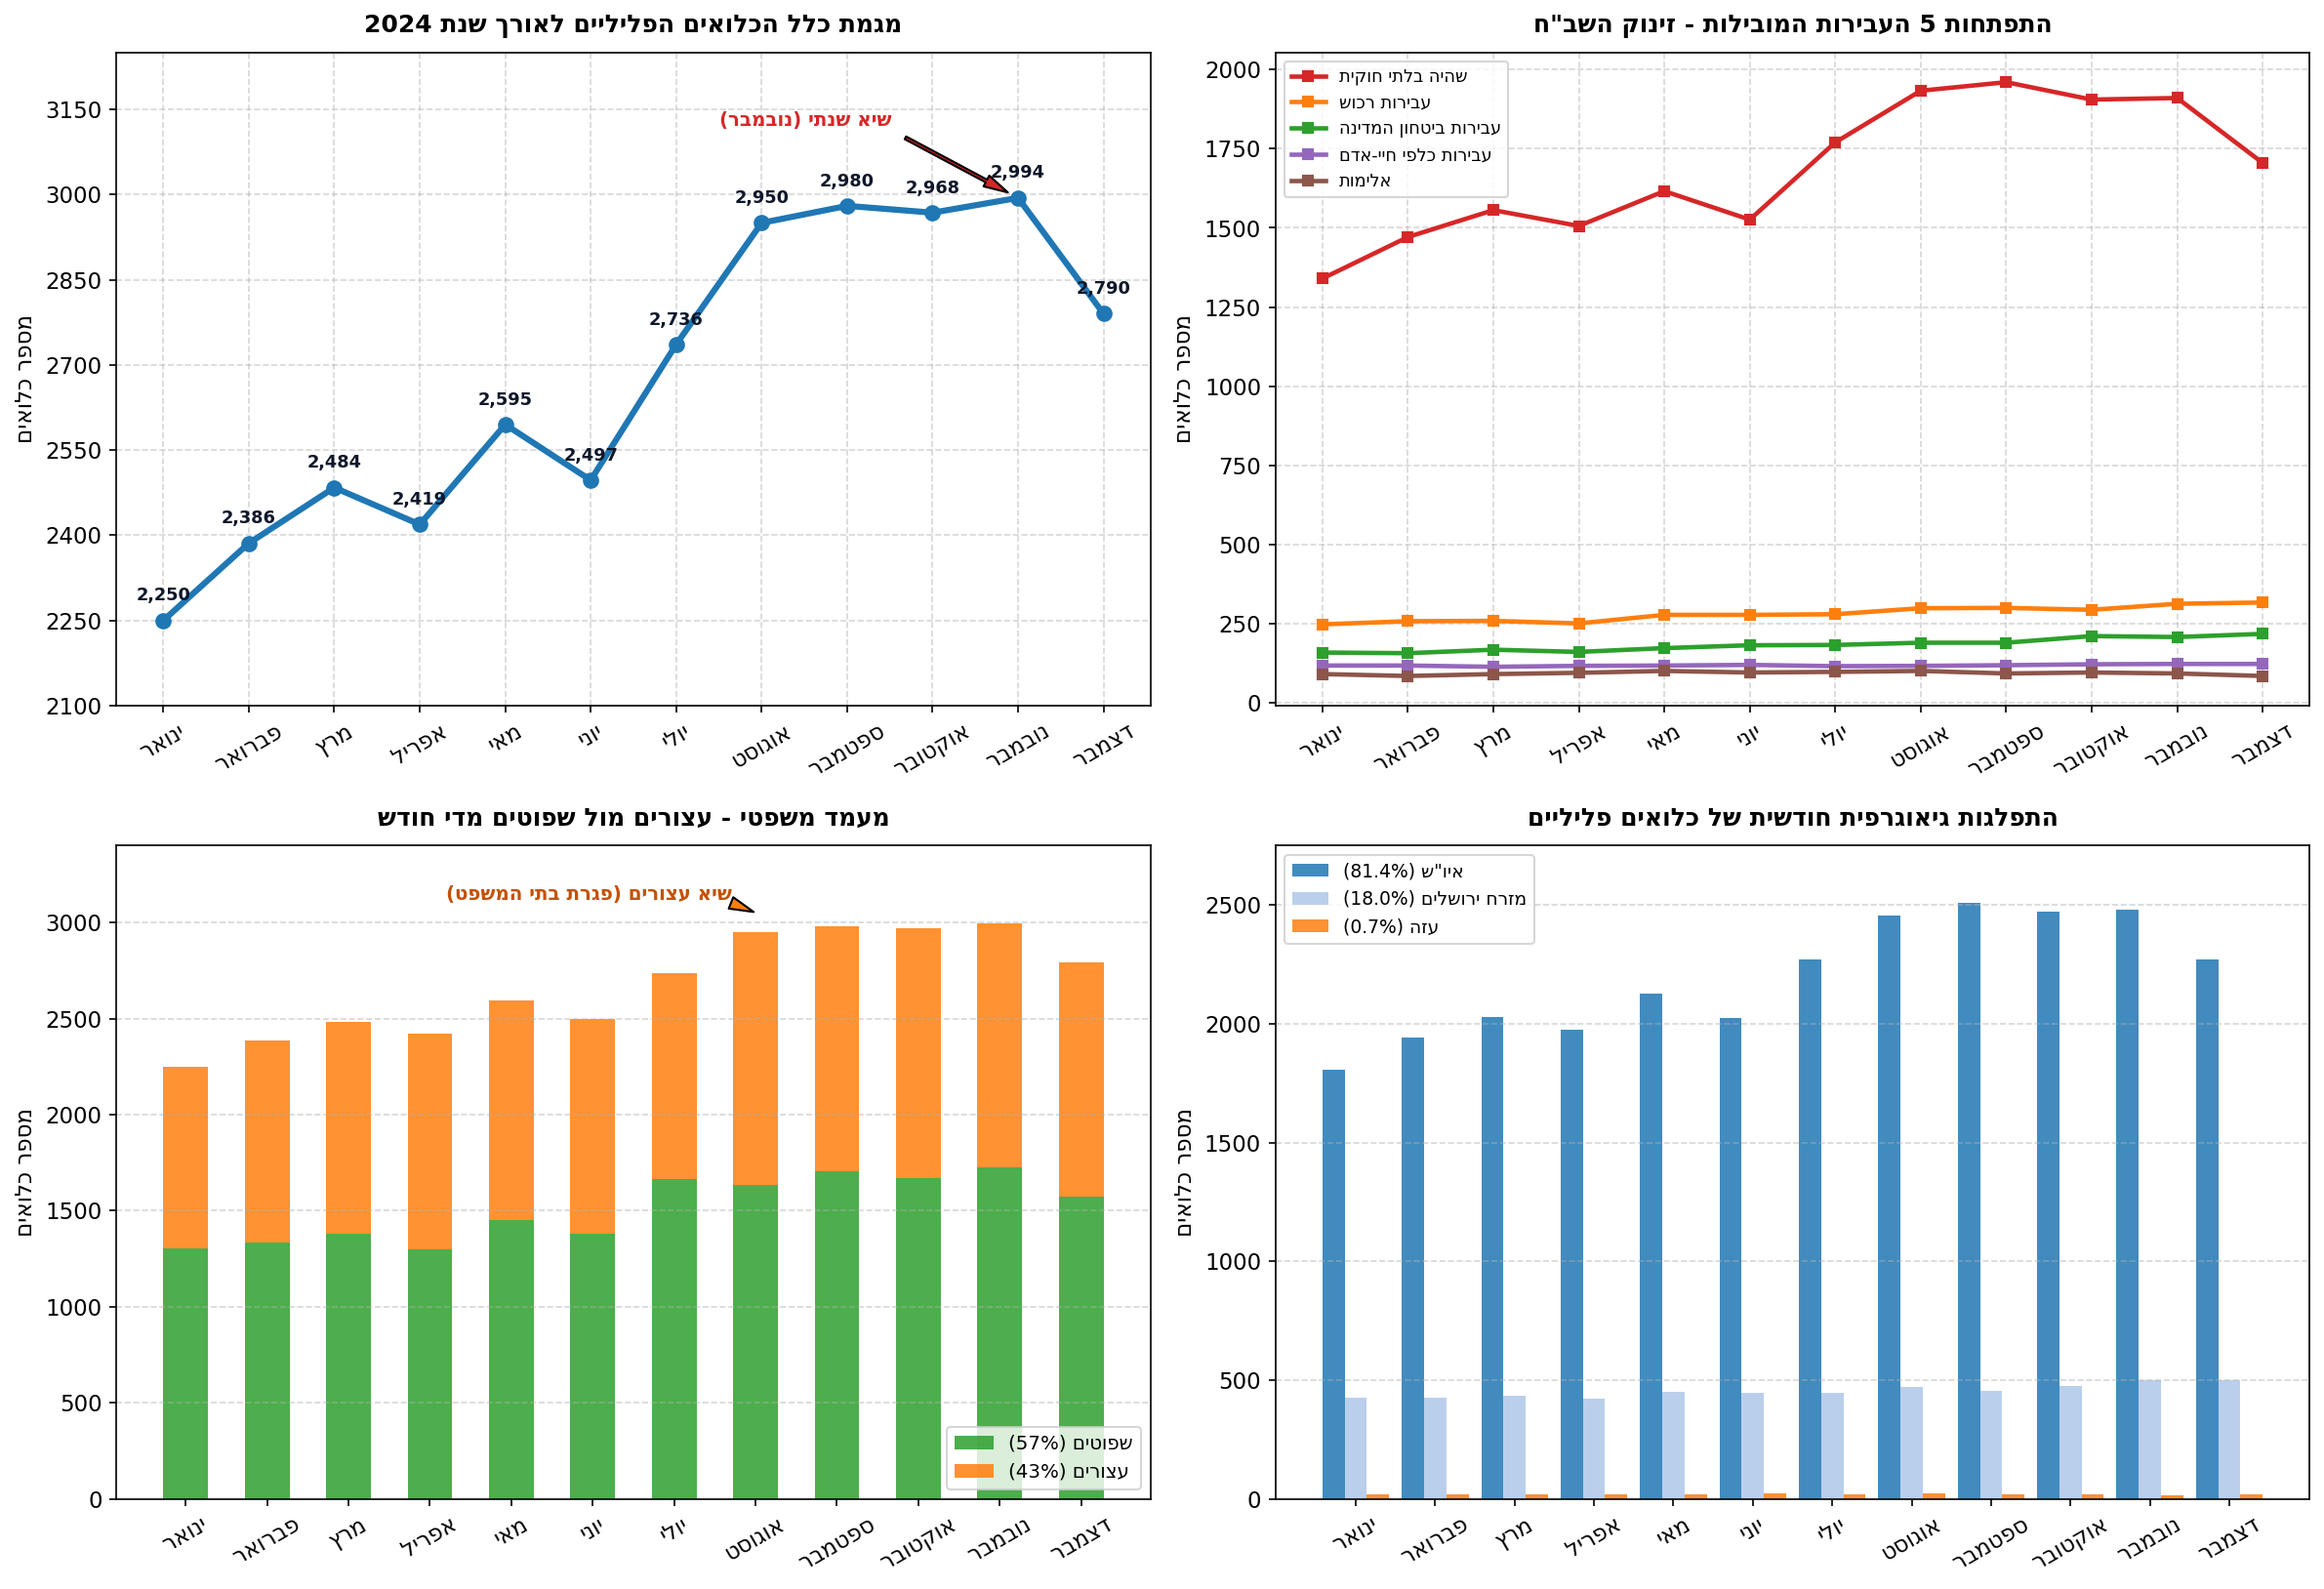

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
plt.subplots_adjust(hspace=0.36, wspace=0.22)
month_labels = [rtl(m) for m in month_names]

# --- גרף 1: מגמת כלל הכלואים לאורך 2024 ---
ax1 = axes[0, 0]
y_vals = monthly_crim['סה"כ כלואים'].values
ax1.plot(month_labels, y_vals, marker='o', color='#1f77b4', linewidth=3, markersize=7)
ax1.set_title(rtl('מגמת כלל הכלואים הפליליים לאורך שנת 2024'), fontsize=12, fontweight='bold', pad=10)
ax1.set_ylabel(rtl('מספר כלואים'), fontsize=11)
ax1.set_ylim(2100, 3250)
ax1.set_yticks(np.arange(2100, 3300, 150))
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.tick_params(axis='x', rotation=30)
for i, val in enumerate(y_vals):
    ax1.annotate(f"{val:,}", (month_labels[i], val + 35), ha='center', fontsize=8.5, fontweight='bold', color='#0f172a')
ax1.annotate(rtl('שיא שנתי (נובמבר)'), xy=(10, 2994), xytext=(6.5, 3120),
             arrowprops=dict(facecolor='#d62728', shrink=0.08, width=1.5, headwidth=6),
             fontsize=9.5, fontweight='bold', color='#d62728')

# --- גרף 2: 5 העבירות המובילות ---
ax2 = axes[0, 1]
top5_off = off_ann.head(5)['עבירה'].tolist()
off_monthly = df_crim[df_crim['עבירה'].isin(top5_off)].pivot_table(
    index='חודש', columns='עבירה', values='סה"כ כלואים', aggfunc='sum', fill_value=0
).reindex(chronological_months)

colors_off = ['#d62728', '#ff7f0e', '#2ca02c', '#9467bd', '#8c564b']
for idx, off in enumerate(top5_off):
    ax2.plot(month_labels, off_monthly[off], marker='s', label=rtl(off), color=colors_off[idx], linewidth=2.2, markersize=5)
ax2.set_title(rtl('התפתחות 5 העבירות המובילות - זינוק השב"ח'), fontsize=12, fontweight='bold', pad=10)
ax2.set_ylabel(rtl('מספר כלואים'), fontsize=11)
ax2.legend(loc='upper left', frameon=True, fontsize=8.5)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.tick_params(axis='x', rotation=30)

# --- גרף 3: מעמד משפטי (עצורים מול שפוטים) ---
ax3 = axes[1, 0]
legal_crim = df_crim.groupby('חודש')[['שפוטים', 'עצורים']].sum().reindex(chronological_months)
sent_vals = legal_crim['שפוטים'].values
rem_vals = legal_crim['עצורים'].values
ax3.bar(month_labels, sent_vals, label=rtl('שפוטים (57%)'), color='#2ca02c', alpha=0.85, width=0.55)
ax3.bar(month_labels, rem_vals, bottom=sent_vals, label=rtl('עצורים (43%)'), color='#ff7f0e', alpha=0.85, width=0.55)
ax3.set_title(rtl('מעמד משפטי - עצורים מול שפוטים מדי חודש'), fontsize=12, fontweight='bold', pad=10)
ax3.set_ylabel(rtl('מספר כלואים'), fontsize=11)
ax3.legend(loc='lower right', frameon=True, fontsize=9.5)
ax3.grid(True, linestyle='--', alpha=0.5, axis='y')
ax3.tick_params(axis='x', rotation=30)
ax3.set_ylim(0, 3400)
ax3.annotate(rtl('שיא עצורים (פגרת בתי המשפט)'), xy=(7, 1418 + sent_vals[7]), xytext=(3.2, 3120),
             arrowprops=dict(facecolor='#ff7f0e', shrink=0.08, width=1.5, headwidth=6),
             fontsize=9.5, fontweight='bold', color='#c45100')

# --- גרף 4: התפלגות גיאוגרפית ---
ax4 = axes[1, 1]
res_crim = df_crim.pivot_table(index='חודש', columns='תושבות', values='סה"כ כלואים', aggfunc='sum', fill_value=0).reindex(chronological_months)
x_indices = np.arange(len(month_names))
w = 0.28
ax4.bar(x_indices - w, res_crim["יו'ש"], width=w, label=rtl('איו"ש (81.4%)'), color='#1f77b4', alpha=0.85)
ax4.bar(x_indices, res_crim['מזרח י-ם'], width=w, label=rtl('מזרח ירושלים (18.0%)'), color='#aec7e8', alpha=0.85)
ax4.bar(x_indices + w, res_crim["אזח'ע"], width=w, label=rtl('עזה (0.7%)'), color='#ff7f0e', alpha=0.85)
ax4.set_xticks(x_indices)
ax4.set_xticklabels(month_labels, rotation=30)
ax4.set_title(rtl('התפלגות גיאוגרפית חודשית של כלואים פליליים'), fontsize=12, fontweight='bold', pad=10)
ax4.set_ylabel(rtl('מספר כלואים'), fontsize=11)
ax4.legend(loc='upper left', frameon=True, fontsize=9)
ax4.grid(True, linestyle='--', alpha=0.5, axis='y')
ax4.set_ylim(0, 2750)

plt.tight_layout()
plt.show()


<div dir="rtl" style="text-align: right; direction: rtl; line-height: 1.6; font-family: 'Segoe UI', Arial, sans-serif;">

### תרשימים: ניתוח עונתיות בקרב קטינים (חופשת הקיץ), מעמד משפטי ופילוח מגדרי
</div>

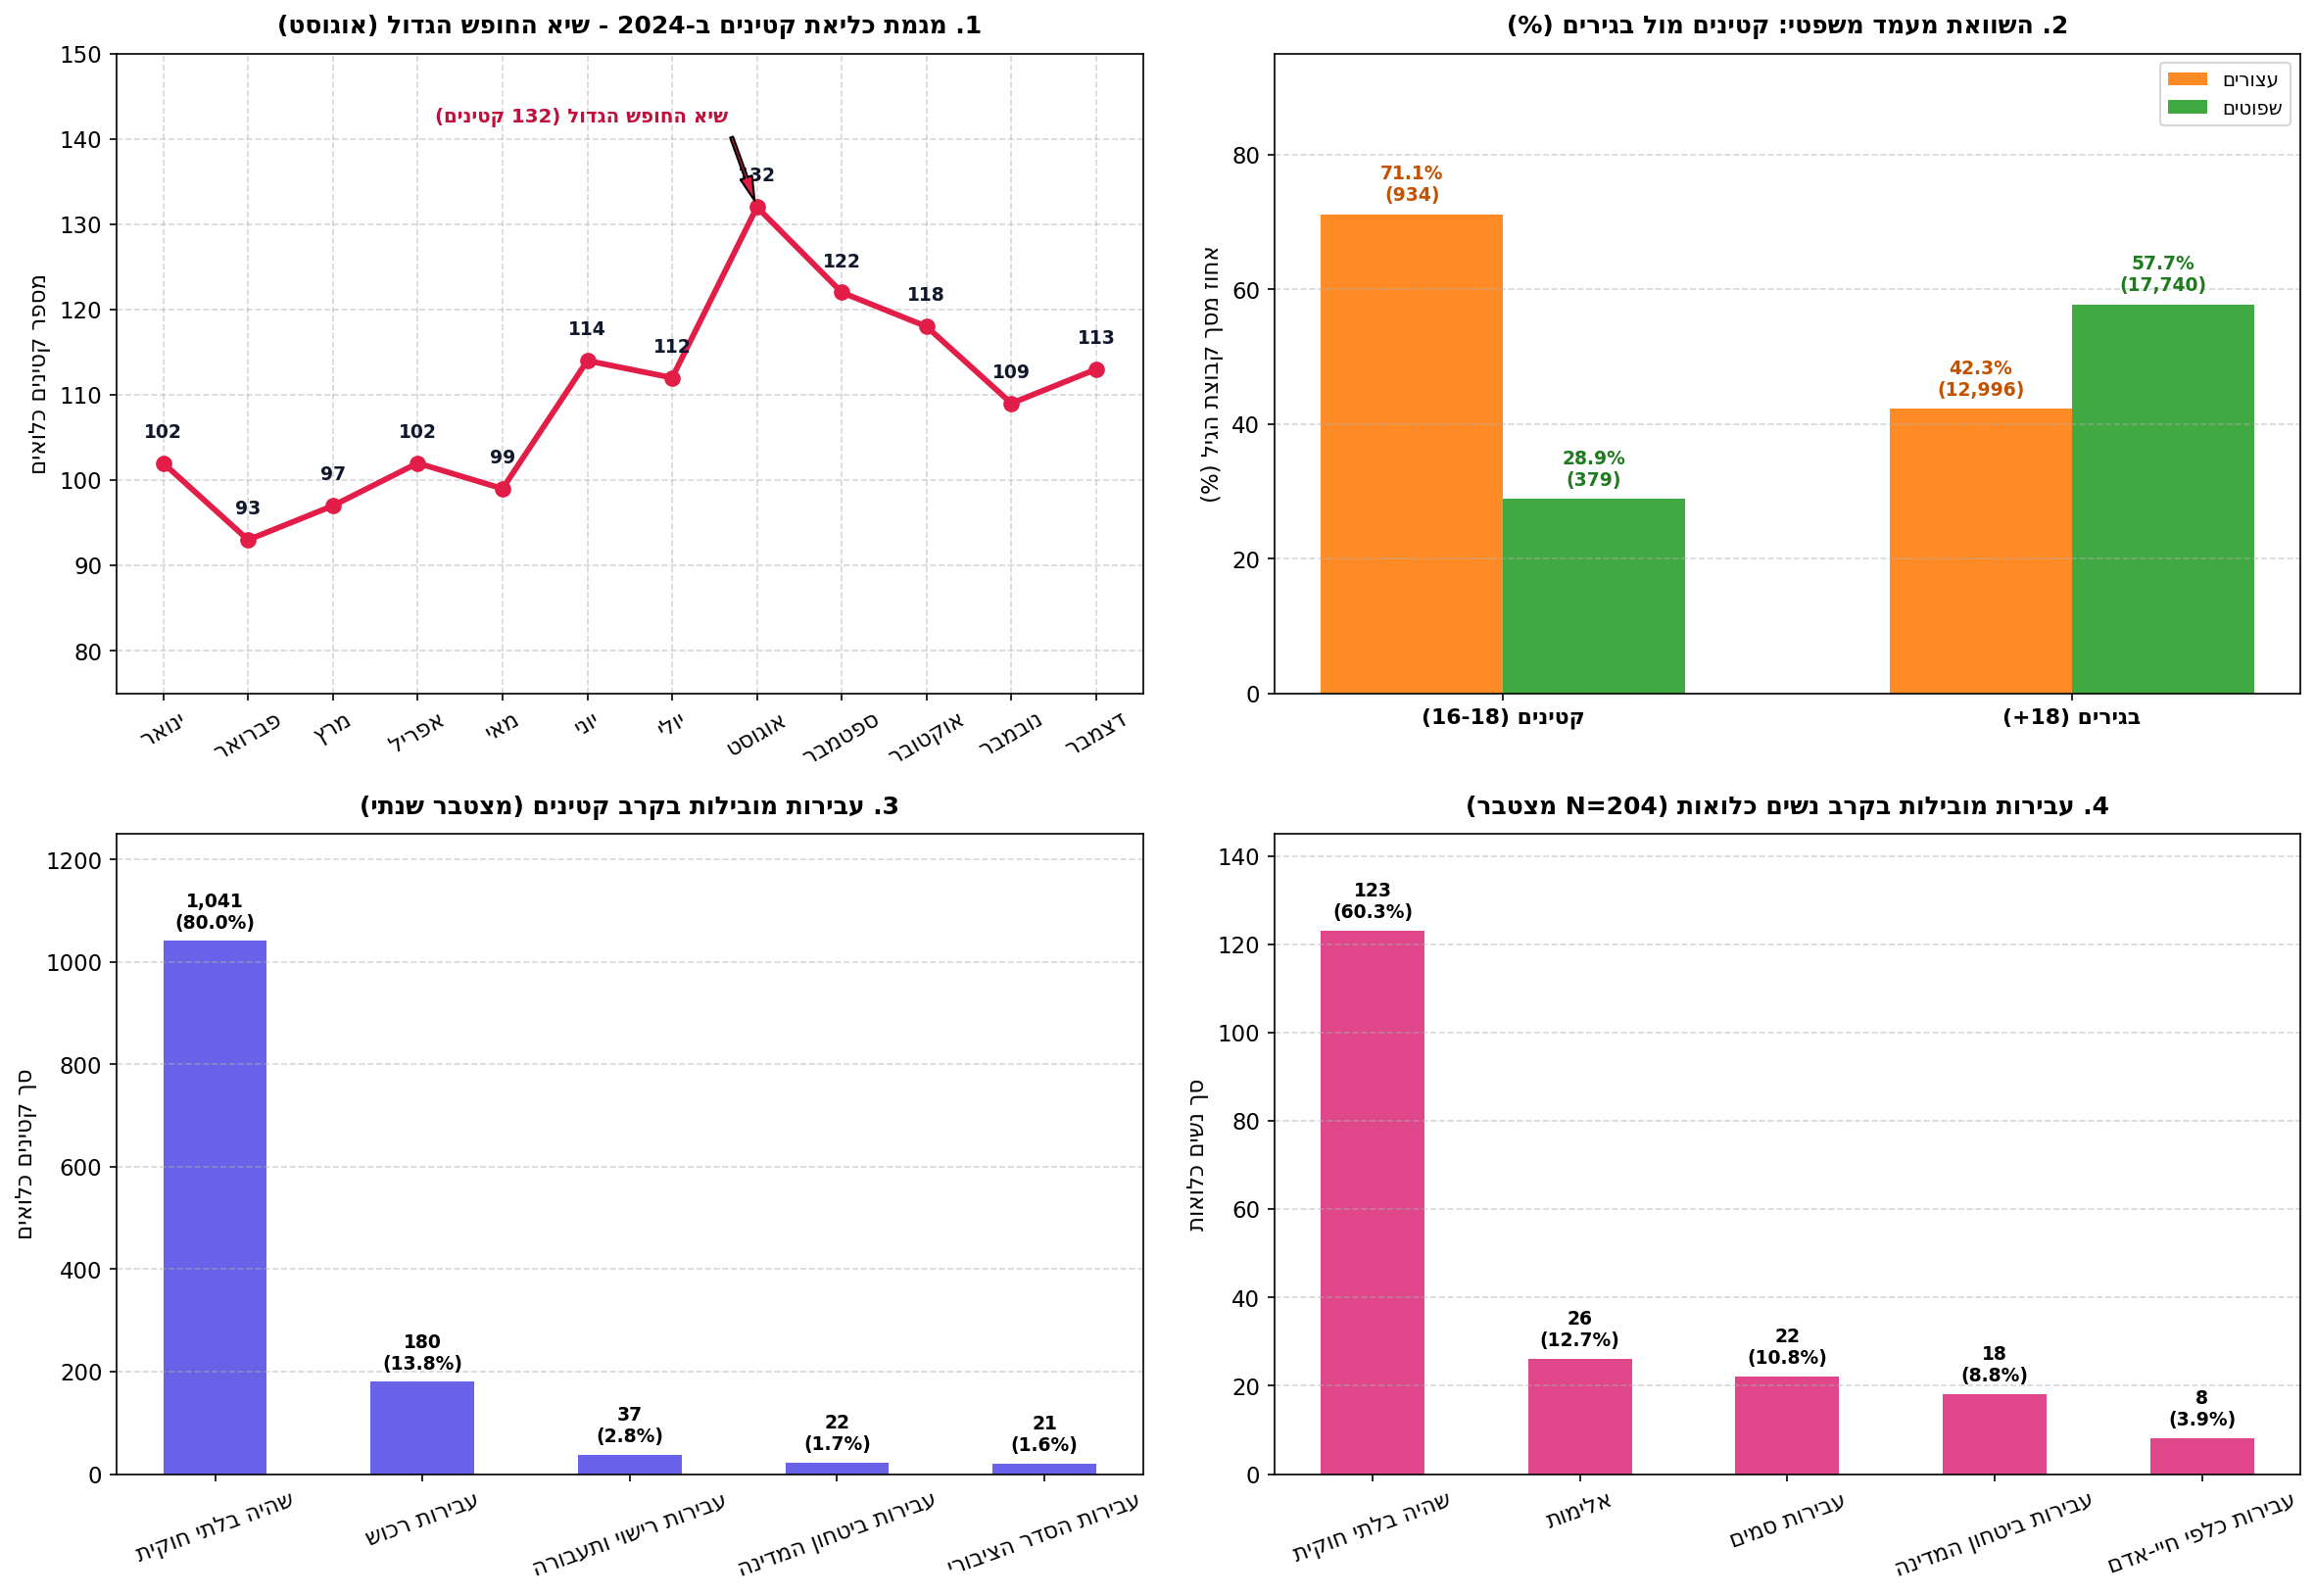

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
plt.subplots_adjust(hspace=0.36, wspace=0.22)

# --- גרף 1: מגמת קטינים לאורך השנה (עונתיות החופש הגדול) ---
ax1 = axes[0, 0]
minors_vals = age_monthly['קטינים'].values
ax1.plot(month_labels, minors_vals, marker='o', color='#e11d48', linewidth=2.8, markersize=7)
ax1.set_title(rtl('1. מגמת כליאת קטינים ב-2024 - שיא החופש הגדול (אוגוסט)'), fontsize=12, fontweight='bold', pad=10)
ax1.set_ylabel(rtl('מספר קטינים כלואים'), fontsize=11)
ax1.set_ylim(75, 150)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.tick_params(axis='x', rotation=30)
for i, v in enumerate(minors_vals):
    ax1.annotate(f"{v}", (month_labels[i], v + 3), ha='center', fontsize=9, fontweight='bold', color='#0f172a')
ax1.annotate(rtl('שיא החופש הגדול (132 קטינים)'), xy=(7, 132), xytext=(3.2, 142),
             arrowprops=dict(facecolor='#e11d48', shrink=0.08, width=1.5, headwidth=6),
             fontsize=9.5, fontweight='bold', color='#be123c')

# --- גרף 2: השוואת שיעורי עצורים מול שפוטים: קטינים מול בגירים ---
ax2 = axes[0, 1]
tot_min_rem = df_crim['קטינים_עצורים'].sum()
tot_min_sent = df_crim['קטינים_שפוטים'].sum()
tot_ad_rem = df_crim['בגירים_עצורים'].sum()
tot_ad_sent = df_crim['בגירים_שפוטים'].sum()

groups = [rtl('קטינים (16-18)'), rtl('בגירים (18+)')]
rem_shares = [tot_min_rem / (tot_min_rem + tot_min_sent) * 100, tot_ad_rem / (tot_ad_rem + tot_ad_sent) * 100]
sent_shares = [tot_min_sent / (tot_min_rem + tot_min_sent) * 100, tot_ad_sent / (tot_ad_rem + tot_ad_sent) * 100]

x2_pos = np.arange(len(groups))
w2_pos = 0.32

b1 = ax2.bar(x2_pos - w2_pos/2, rem_shares, width=w2_pos, label=rtl('עצורים'), color='#ff7f0e', alpha=0.9)
b2 = ax2.bar(x2_pos + w2_pos/2, sent_shares, width=w2_pos, label=rtl('שפוטים'), color='#2ca02c', alpha=0.9)

ax2.set_xticks(x2_pos)
ax2.set_xticklabels(groups, fontsize=10.5, fontweight='bold')
ax2.set_title(rtl('2. השוואת מעמד משפטי: קטינים מול בגירים (%)'), fontsize=12, fontweight='bold', pad=10)
ax2.set_ylabel(rtl('אחוז מסך קבוצת הגיל (%)'), fontsize=11)
ax2.set_ylim(0, 95)
ax2.legend(loc='upper right', frameon=True, fontsize=9.5)
ax2.grid(True, linestyle='--', alpha=0.5, axis='y')

ax2.annotate(f"{rem_shares[0]:.1f}%\n({tot_min_rem:,})", (x2_pos[0] - w2_pos/2, rem_shares[0] + 2), ha='center', fontsize=9, fontweight='bold', color='#c45100')
ax2.annotate(f"{sent_shares[0]:.1f}%\n({tot_min_sent:,})", (x2_pos[0] + w2_pos/2, sent_shares[0] + 2), ha='center', fontsize=9, fontweight='bold', color='#1e7b1e')

ax2.annotate(f"{rem_shares[1]:.1f}%\n({tot_ad_rem:,})", (x2_pos[1] - w2_pos/2, rem_shares[1] + 2), ha='center', fontsize=9, fontweight='bold', color='#c45100')
ax2.annotate(f"{sent_shares[1]:.1f}%\n({tot_ad_sent:,})", (x2_pos[1] + w2_pos/2, sent_shares[1] + 2), ha='center', fontsize=9, fontweight='bold', color='#1e7b1e')

# --- גרף 3: עבירות מובילות בקרב קטינים ---
ax3 = axes[1, 0]
min_off = df_crim.groupby('עבירה')['קטינים'].sum().sort_values(ascending=False).head(5)
bars3 = ax3.bar([rtl(x) for x in min_off.index], min_off.values, color='#4f46e5', alpha=0.85, width=0.5)
ax3.set_title(rtl('3. עבירות מובילות בקרב קטינים (מצטבר שנתי)'), fontsize=12, fontweight='bold', pad=10)
ax3.set_ylabel(rtl('סך קטינים כלואים'), fontsize=11)
ax3.grid(True, linestyle='--', alpha=0.5, axis='y')
ax3.tick_params(axis='x', rotation=20)
ax3.set_ylim(0, 1250)
for bar in bars3:
    h = bar.get_height()
    ax3.annotate(f"{h:,}\n({h/min_off.sum()*100:.1f}%)", (bar.get_x() + bar.get_width()/2, h + 25), ha='center', fontsize=9, fontweight='bold')

# --- גרף 4: עבירות מובילות בקרב נשים כלואות ---
ax4 = axes[1, 1]
fem_off = df_crim[df_crim['מגדר'] == 'נשים'].groupby('עבירה')['סה"כ כלואים'].sum().sort_values(ascending=False).head(5)
bars4 = ax4.bar([rtl(x) for x in fem_off.index], fem_off.values, color='#db2777', alpha=0.85, width=0.5)
ax4.set_title(rtl('4. עבירות מובילות בקרב נשים כלואות (N=204 מצטבר)'), fontsize=12, fontweight='bold', pad=10)
ax4.set_ylabel(rtl('סך נשים כלואות'), fontsize=11)
ax4.grid(True, linestyle='--', alpha=0.5, axis='y')
ax4.tick_params(axis='x', rotation=20)
ax4.set_ylim(0, 145)
for bar in bars4:
    h = bar.get_height()
    ax4.annotate(f"{h:,}\n({h/204*100:.1f}%)", (bar.get_x() + bar.get_width()/2, h + 3), ha='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


<div dir="rtl" style="text-align: right; direction: rtl; line-height: 1.7; font-family: 'Segoe UI', Arial, sans-serif;">

---
# פרק ב': ניתוח האוכלוסייה הביטחונית ושיוך ארגוני (גיליון 3)

### אבני דרך והתפתחויות ביטחוניות מרכזיות לאורך שנת 2024:
1. **ינואר (8,602 כלואים):** תמונת הפתיחה השנתית. פת"ח הוביל כארגון הגדול ביותר (3,642 כלואים / 42.3%), וחמאס במקום השני (3,278 כלואים / 38.1%).
2. **מרץ (9,065 כלואים):** כוננות מוגברת ומבצעי מעצרים רחבים ביהודה ושומרון לקראת חודש הרמדאן.
3. **יולי (9,662 כלואים):** **נקודת המפנה במלחמה (מבצע רפיח):** חמאס (3,911 כלואים) עוקף לראשונה את פת"ח (3,819 כלואים), עקב מעצר מאות פעילי שטח ולוחמים בעזה.
4. **אוקטובר (9,944 כלואים):** יום השנה למתקפת 7 באוקטובר וכוננות תקופת החגים, שהובילו למעצרי מנע נוספים בירושלים וביו"ש.
5. **דצמבר (10,097 כלואים / עלייה של 17.4% מינואר):** חציית רף 10,000 הכלואים. פת"ח סיים ב-4,071, חמאס ב-3,868, וקטגוריית "ללא שיוך מוגדר" (מפגעים בודדים) זינקה ל-772 כלואים (עלייה של **127.1%**).
</div>

In [6]:
records_sec = []

for q_name, file in file_map.items():
    df_raw = pd.read_excel(file, sheet_name=2, header=None)
    current_month = None
    current_status = None
    
    for row_idx in range(len(df_raw)):
        row = df_raw.iloc[row_idx].tolist()
        for cell in row:
            if pd.notna(cell):
                cell_s = str(cell).strip()
                for m in month_names:
                    if m in cell_s and '2024' in cell_s:
                        current_month = f"{m} 2024"
                        break
                        
        c4 = str(row[4]).strip() if len(row) > 4 and pd.notna(row[4]) else ''
        if c4 and c4 not in ['nan', 'סה"כ'] and not any(x in c4 for x in ['ארגון', 'פח"ע', '18-16', 'בגירים', 'עד 16']):
            current_status = c4
            
        c5 = str(row[5]).strip() if len(row) > 5 and pd.notna(row[5]) else ''
        if c5 and c5 not in ['ארגון פח"ע', 'ארגון פחע', 'nan', 'סה"כ', '18-16', 'בגירים', 'עד 16']:
            nums = [pd.to_numeric(x, errors='coerce') for x in row[6:] if pd.notna(x)]
            nums = [n for n in nums if not np.isnan(n)]
            total = int(sum(nums))
            if total > 0 and current_month and current_status:
                records_sec.append({
                    'רבעון': q_name,
                    'חודש': current_month,
                    'מעמד כליאה': current_status,
                    'ארגון': c5,
                    'סה"כ כלואים': total
                })

df_sec = pd.DataFrame(records_sec)
df_sec['מספר חודש'] = df_sec['חודש'].apply(lambda x: month_names.index(x.split()[0]) + 1)
df_sec = df_sec.sort_values('מספר חודש').reset_index(drop=True)
print(f"✓ נטענו בהצלחה {len(df_sec):,} רשומות ביטחוניות ב-12 החודשים של 2024.")


✓ נטענו בהצלחה 549 רשומות ביטחוניות ב-12 החודשים של 2024.


<div dir="rtl" style="text-align: right; direction: rtl; line-height: 1.6; font-family: 'Segoe UI', Arial, sans-serif;">

### טבלאות נתונים: שיוך ארגוני, שיעורי צמיחה ומעמדות כליאה ביטחוניים
</div>

In [7]:
# 1. התפתחות 6 הארגונים המובילים
org_monthly_pivot = df_sec.pivot_table(
    index='חודש', columns='ארגון', values='סה"כ כלואים', aggfunc='sum', fill_value=0
).reindex(chronological_months)

top_orgs = df_sec.groupby('ארגון')['סה"כ כלואים'].sum().nlargest(6).index.tolist()
org_top6_monthly = org_monthly_pivot[top_orgs]
org_top6_monthly['סה"כ כלל המחבלים'] = df_sec.groupby('חודש')['סה"כ כלואים'].sum().reindex(chronological_months)

t6_styled = org_top6_monthly.reset_index()
for col in top_orgs + ['סה"כ כלל המחבלים']:
    t6_styled[col] = t6_styled[col].apply(lambda x: f"{x:,}")
show_rtl_table(t6_styled, "טבלה 6: התפתחות חודשית של 6 ארגוני הטרור המובילים לאורך 2024")

# 2. שיעורי צמיחה ונתחי שוק
growth_data = []
for org in top_orgs:
    jan_v = org_monthly_pivot.loc['ינואר 2024', org]
    dec_v = org_monthly_pivot.loc['דצמבר 2024', org]
    pct_growth = ((dec_v - jan_v) / jan_v * 100).round(1)
    jan_share = (jan_v / org_top6_monthly.loc['ינואר 2024', 'סה"כ כלל המחבלים'] * 100).round(1)
    dec_share = (dec_v / org_top6_monthly.loc['דצמבר 2024', 'סה"כ כלל המחבלים'] * 100).round(1)
    
    growth_data.append({
        'ארגון': org,
        'ינואר 2024': f"{jan_v:,}",
        'דצמבר 2024': f"{dec_v:,}",
        'שינוי נטו': f"{dec_v - jan_v:+,}",
        'שיעור שינוי': f"{pct_growth:+.1f}%",
        'נתח שוק בינואר': f"{jan_share:.1f}%",
        'נתח שוק בדצמבר': f"{dec_share:.1f}%"
    })

t7_styled = pd.DataFrame(growth_data)
show_rtl_table(t7_styled, "טבלה 7: השוואת שיעורי צמיחה ונתחי שוק (ינואר מול דצמבר 2024)")

# 3. הצלבת מעמד כליאה מול ארגון
status_org_crosstab = df_sec.pivot_table(
    index='מעמד כליאה', columns='ארגון', values='סה"כ כלואים', aggfunc='sum', fill_value=0
)[top_orgs].reset_index()

for col in top_orgs:
    status_org_crosstab[col] = status_org_crosstab[col].apply(lambda x: f"{x:,}")
show_rtl_table(status_org_crosstab, "טבלה 8: פילוח שיוך ארגוני לפי מעמד כליאה (מצטבר שנתי)")

# 4. התפתחות מעמדות הכליאה במלחמה
sec_status_monthly = df_sec.pivot_table(
    index='חודש', columns='מעמד כליאה', values='סה"כ כלואים', aggfunc='sum', fill_value=0
).reindex(chronological_months)[['עצור מנהלי בטחוני', "עצור בטחוני עת'ה", 'שפוט בטחוני', 'לוחם בלתי חוקי בטחוני']].reset_index()

for col in ['עצור מנהלי בטחוני', "עצור בטחוני עת'ה", 'שפוט בטחוני', 'לוחם בלתי חוקי בטחוני']:
    sec_status_monthly[col] = sec_status_monthly[col].apply(lambda x: f"{x:,}")

show_rtl_table(sec_status_monthly, "טבלה 9: התפתחות חודשית של 4 מעמדות הכליאה הביטחוניים המרכזיים ב-2024")


חודש,אל-פתח,חמ'ס,ג'יהאד אל איסלאמי,לא מוגדר,חז'ע,חז'ד,"סה""כ כלל המחבלים"
ינואר 2024,"3,642","3,278",726,340,417,131,"8,602"
פברואר 2024,"3,620","3,391",750,447,416,126,"8,819"
מרץ 2024,"3,763","3,455",784,443,421,126,"9,065"
אפריל 2024,"3,732","3,278",759,505,422,119,"8,890"
מאי 2024,"3,787","3,271",768,502,414,119,"8,937"
יוני 2024,"3,866","3,709",764,510,401,113,"9,440"
יולי 2024,"3,819","3,911",785,564,398,107,"9,662"
אוגוסט 2024,"3,913","3,797",781,604,391,103,"9,668"
ספטמבר 2024,"3,987","3,858",788,640,399,103,"9,856"
אוקטובר 2024,"4,027","3,867",804,654,399,106,"9,944"


ארגון,ינואר 2024,דצמבר 2024,שינוי נטו,שיעור שינוי,נתח שוק בינואר,נתח שוק בדצמבר
אל-פתח,"3,642","4,071",+429,+11.8%,42.3%,40.3%
חמ'ס,"3,278","3,868",+590,+18.0%,38.1%,38.3%
ג'יהאד אל איסלאמי,726,794,+68,+9.4%,8.4%,7.9%
לא מוגדר,340,772,+432,+127.1%,4.0%,7.6%
חז'ע,417,389,-28,-6.7%,4.8%,3.9%
חז'ד,131,102,-29,-22.1%,1.5%,1.0%


מעמד כליאה,אל-פתח,חמ'ס,ג'יהאד אל איסלאמי,לא מוגדר,חז'ע,חז'ד
לוחם בלתי חוקי בטחוני,130,"13,957",389,979,30,11
עצור בטחוני עה'א,335,128,8,415,25,4
עצור בטחוני עת'ה,"13,908","6,066","2,803","2,081","1,207",330
עצור לימים בטחוני,396,"2,205",214,682,42,8
עצור מנהלי בטחוני,"17,613","15,003","4,015","1,453","2,546",534
שפוט בטחוני,"13,889","6,229","1,877","1,075","1,016",470


חודש,עצור מנהלי בטחוני,עצור בטחוני עת'ה,שפוט בטחוני,לוחם בלתי חוקי בטחוני
ינואר 2024,"3,489","1,943","2,100",604
פברואר 2024,"3,550","2,045","2,082",794
מרץ 2024,"3,662","2,117","2,092",849
אפריל 2024,"3,433","2,164","2,091",865
מאי 2024,"3,411","2,191","2,094",898
יוני 2024,"3,377","2,208","2,087","1,415"
יולי 2024,"3,412","2,224","2,100","1,584"
אוגוסט 2024,"3,325","2,254","2,088","1,612"
ספטמבר 2024,"3,402","2,341","2,068","1,618"
אוקטובר 2024,"3,436","2,407","2,018","1,623"


<div dir="rtl" style="text-align: right; direction: rtl; line-height: 1.6; font-family: 'Segoe UI', Arial, sans-serif;">

### תרשימים: התפתחות שיוך ארגוני, שיעורי שינוי, לוחמים בלתי חוקיים ונתחי שוק
</div>

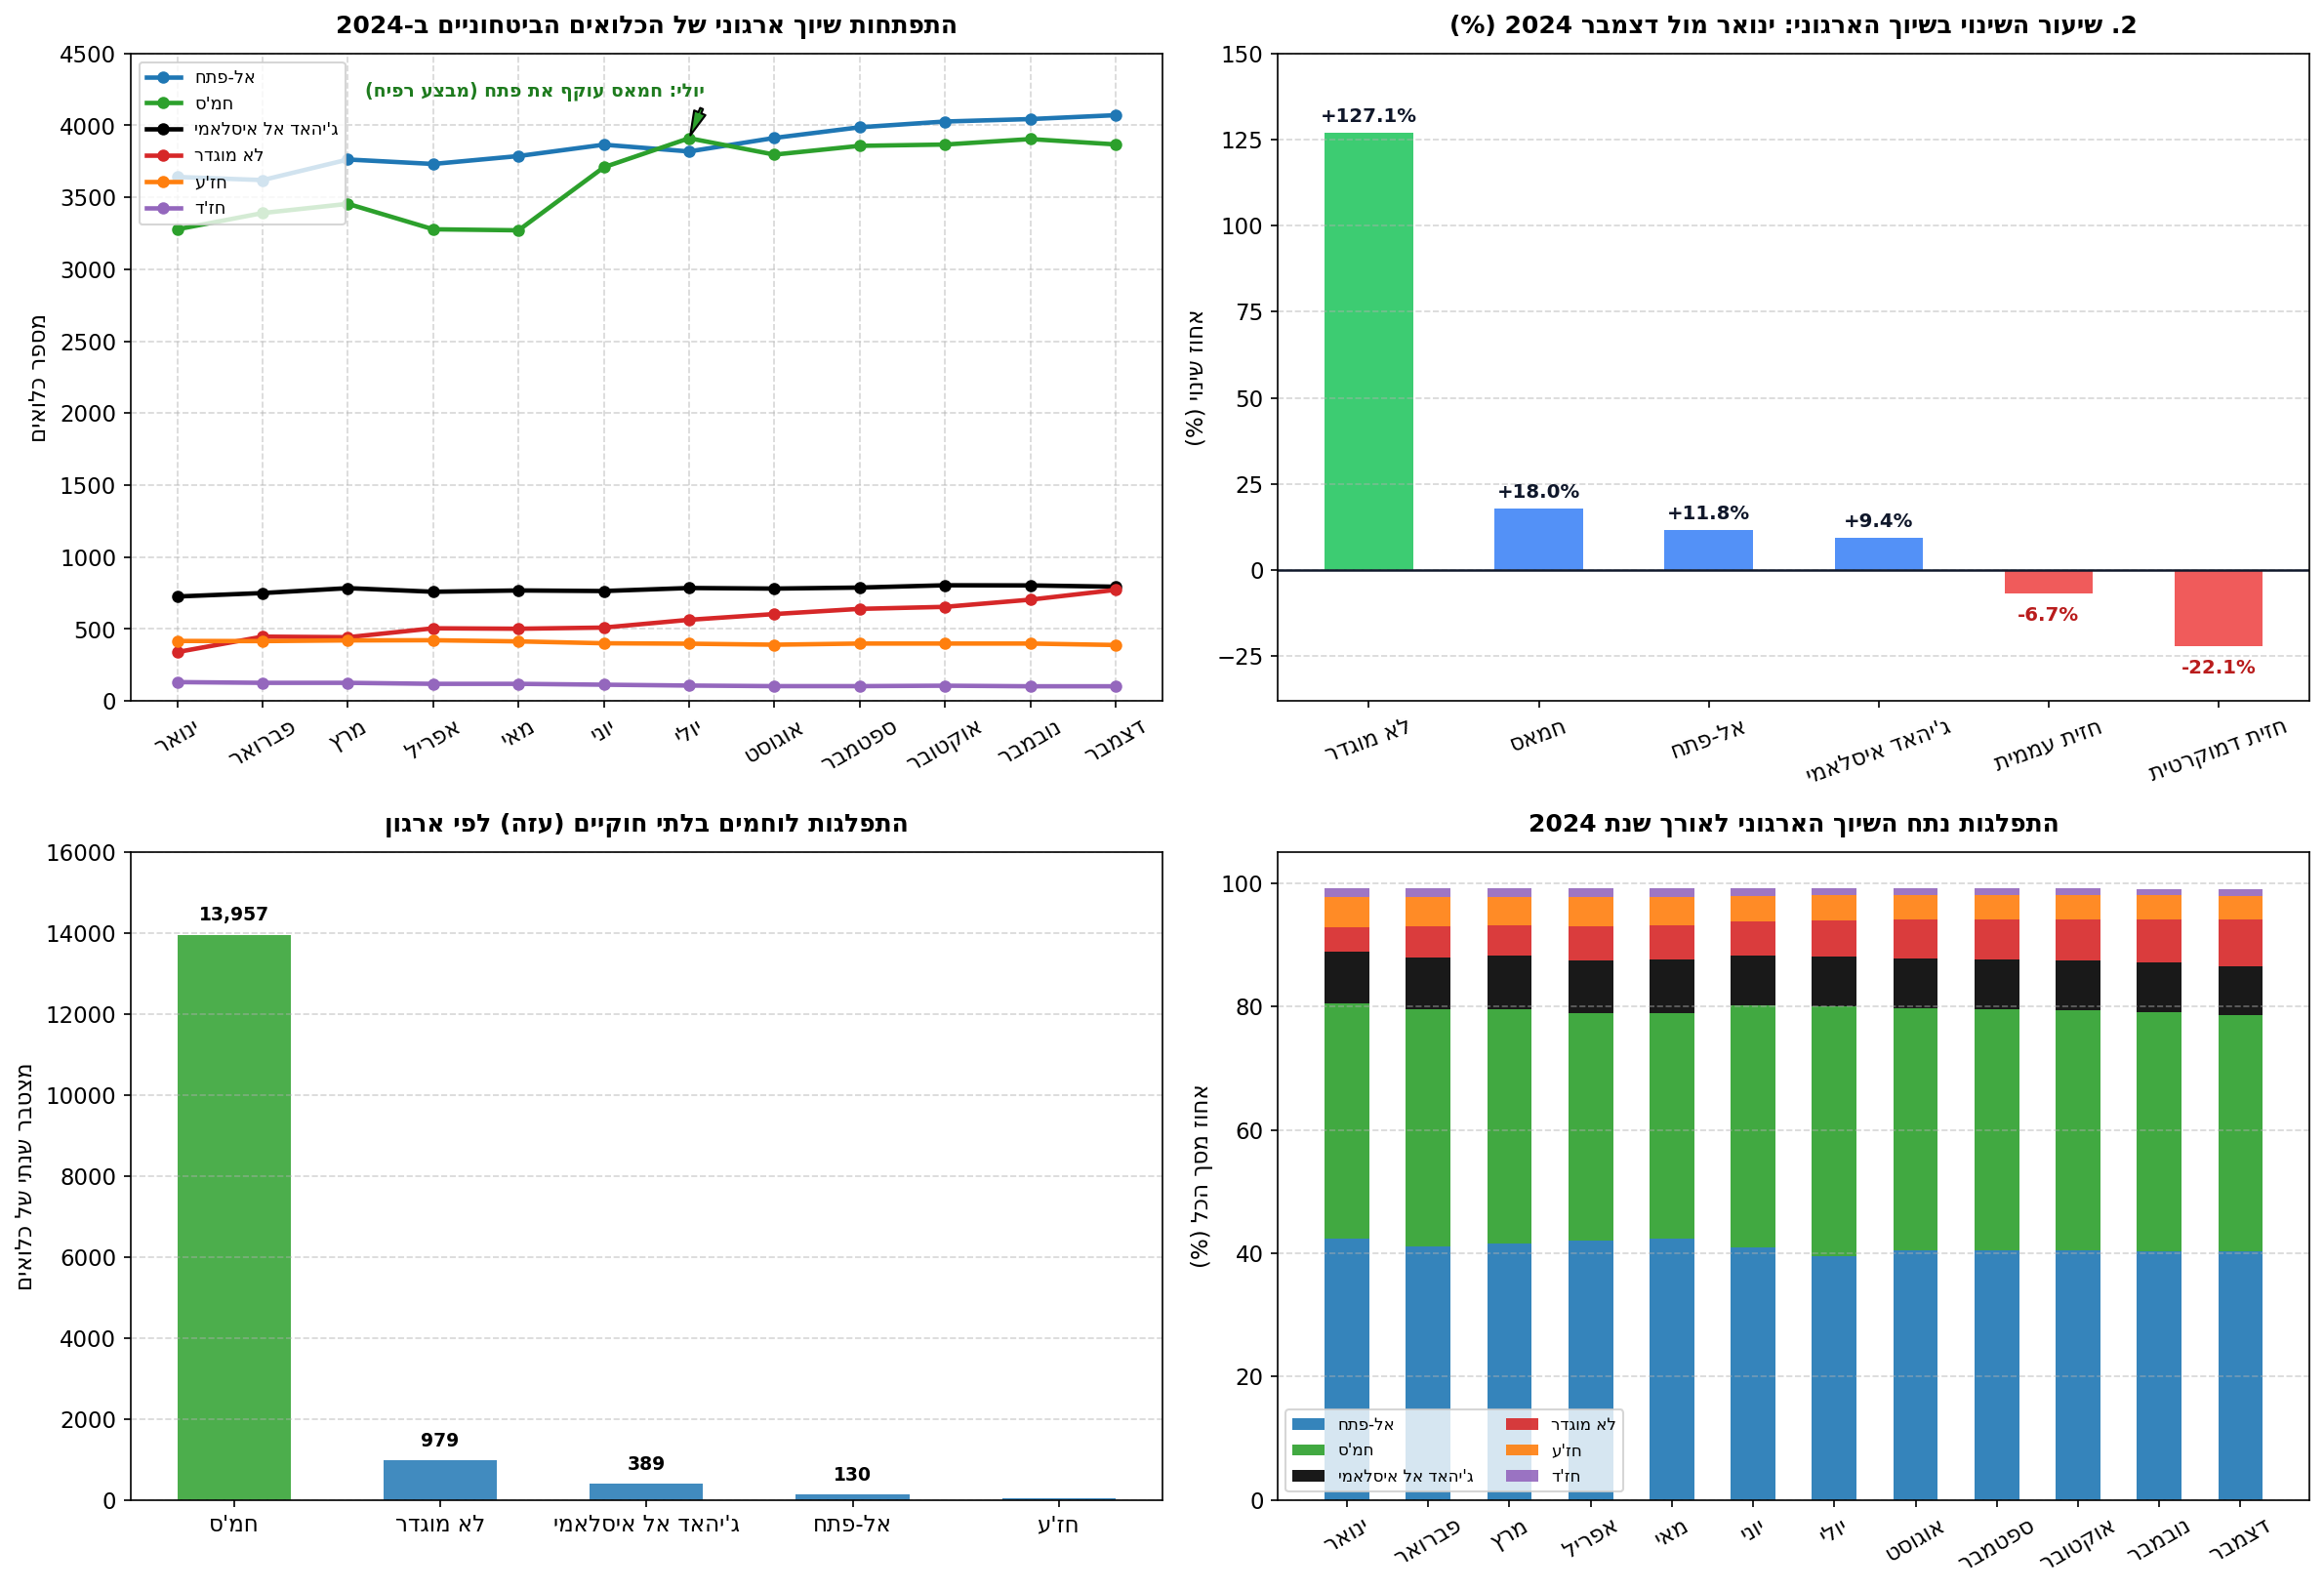

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
plt.subplots_adjust(hspace=0.36, wspace=0.22)

org_colors = {
    'אל-פתח': '#1f77b4',
    "חמ'ס": '#2ca02c',
    "ג'יהאד אל איסלאמי": '#000000',
    'לא מוגדר': '#d62728',
    "חז'ע": '#ff7f0e',
    "חז'ד": '#9467bd'
}

# --- גרף 1: התפתחות 6 הארגונים המובילים לאורך 2024 ---
ax1 = axes[0, 0]
for org in top_orgs:
    ax1.plot(month_labels, org_monthly_pivot[org], marker='o', label=rtl(org),
             color=org_colors.get(org, '#7f7f7f'), linewidth=2.2, markersize=5)

ax1.set_title(rtl('התפתחות שיוך ארגוני של הכלואים הביטחוניים ב-2024'), fontsize=12, fontweight='bold', pad=10)
ax1.set_ylabel(rtl('מספר כלואים'), fontsize=11)
ax1.legend(loc='upper left', frameon=True, fontsize=8.5)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.tick_params(axis='x', rotation=30)
ax1.set_ylim(0, 4500)
ax1.annotate(rtl('יולי: חמאס עוקף את פתח (מבצע רפיח)'), xy=(6, 3911), xytext=(2.2, 4200),
             arrowprops=dict(facecolor='#2ca02c', shrink=0.08, width=1.5, headwidth=6),
             fontsize=9, fontweight='bold', color='#1e7b1e')

# --- גרף 2: שיעור שינוי בשיוך ארגוני (עמודות אנכיות ברורות) ---
ax2 = axes[0, 1]
growth_raw = []
for org in top_orgs:
    j = org_monthly_pivot.loc['ינואר 2024', org]
    d = org_monthly_pivot.loc['דצמבר 2024', org]
    growth_raw.append({'ארגון': org, 'שינוי': ((d - j) / j * 100)})
df_gr_plot = pd.DataFrame(growth_raw).sort_values('שינוי', ascending=False)

org_clean_names = {
    'לא מוגדר': 'לא מוגדר',
    "חמ'ס": 'חמאס',
    'אל-פתח': 'אל-פתח',
    "ג'יהאד אל איסלאמי": "ג'יהאד איסלאמי",
    "חז'ע": 'חזית עממית',
    "חז'ד": 'חזית דמוקרטית'
}
bars2_labels = [rtl(org_clean_names.get(x, x)) for x in df_gr_plot['ארגון'].tolist()]
bars2_vals = df_gr_plot['שינוי'].tolist()
bars2_colors = ['#22c55e' if v > 50 else '#3b82f6' if v > 0 else '#ef4444' for v in bars2_vals]

bars2 = ax2.bar(bars2_labels, bars2_vals, color=bars2_colors, alpha=0.88, width=0.52)
ax2.axhline(0, color='#0f172a', linewidth=1.2)
ax2.set_title(rtl('2. שיעור השינוי בשיוך הארגוני: ינואר מול דצמבר 2024 (%)'), fontsize=12, fontweight='bold', pad=10)
ax2.set_ylabel(rtl('אחוז שינוי (%)'), fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.5, axis='y')
ax2.tick_params(axis='x', rotation=20)
ax2.set_ylim(-38, 150)

for bar, v in zip(bars2, bars2_vals):
    if v >= 0:
        ax2.annotate(f"+{v:.1f}%", (bar.get_x() + bar.get_width()/2, v + 3), ha='center', fontsize=9.5, fontweight='bold', color='#0f172a')
    else:
        ax2.annotate(f"{v:.1f}%", (bar.get_x() + bar.get_width()/2, v - 8), ha='center', fontsize=9.5, fontweight='bold', color='#b91c1c')

# --- גרף 3: פילוח מעמד לוחם בלתי חוקי לפי ארגון ---
ax3 = axes[1, 0]
raw_status_org = df_sec.pivot_table(index='מעמד כליאה', columns='ארגון', values='סה"כ כלואים', aggfunc='sum', fill_value=0)
if 'לוחם בלתי חוקי בטחוני' in raw_status_org.index:
    illegal_combatants = raw_status_org.loc['לוחם בלתי חוקי בטחוני'].sort_values(ascending=False).head(5)
    bars3 = ax3.bar([rtl(x) for x in illegal_combatants.index], illegal_combatants.values,
                    color=['#2ca02c' if 'חמ' in x else '#1f77b4' for x in illegal_combatants.index], alpha=0.85, width=0.55)
    ax3.set_title(rtl('התפלגות לוחמים בלתי חוקיים (עזה) לפי ארגון'), fontsize=12, fontweight='bold', pad=10)
    ax3.set_ylabel(rtl('מצטבר שנתי של כלואים'), fontsize=11)
    ax3.grid(True, linestyle='--', alpha=0.5, axis='y')
    ax3.set_ylim(0, 16000)
    for bar in bars3:
        h = bar.get_height()
        if h > 50:
            ax3.annotate(f"{int(h):,}", (bar.get_x() + bar.get_width()/2, h + 350),
                         ha='center', fontsize=9, fontweight='bold')

# --- גרף 4: נתח שוק יחסי של הארגונים לאורך השנה ---
ax4 = axes[1, 1]
shares_top = org_top6_monthly[top_orgs].div(org_top6_monthly['סה"כ כלל המחבלים'], axis=0) * 100
bottom_cum = np.zeros(len(chronological_months))

for org in top_orgs:
    vals = shares_top[org].values
    ax4.bar(month_labels, vals, bottom=bottom_cum, label=rtl(org), color=org_colors.get(org, '#7f7f7f'), width=0.55, alpha=0.9)
    bottom_cum += vals

ax4.set_title(rtl('התפלגות נתח השיוך הארגוני לאורך שנת 2024'), fontsize=12, fontweight='bold', pad=10)
ax4.set_ylabel(rtl('אחוז מסך הכל (%)'), fontsize=11)
ax4.set_ylim(0, 105)
ax4.legend(loc='lower left', frameon=True, fontsize=8, ncol=2)
ax4.grid(True, linestyle='--', alpha=0.5, axis='y')
ax4.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()


<div dir="rtl" style="text-align: right; direction: rtl; line-height: 1.7; font-family: 'Segoe UI', Arial, sans-serif;">

---
# פרק ג': לקחים והמלצות מעשיות לתכנון המערך

מתוך ניתוח נתוני הכליאה לאורך שנת 2024, עולים מספר לקחים מרכזיים להיערכות ותכנון נכון של שב"ס:

1. **היערכות מראש לקליטת בני נוער בחודשי הקיץ:**  
   הנתונים מראים עלייה חדה בכליאת קטינים בחודש אוגוסט (שיא של 132 קטינים) ושיעור גבוה במיוחד של עצורים (כ-71%). מומלץ להיערך מראש כבר בחודשים מאי–יוני עם תגבור צוותים ומקומות כליאה ייעודיים לנוער, ובמקביל לפעול מול שירות המבחן להרחבת חלופות מעצר בקהילה שימנעו כניסת נוער לכלא.

2. **הקמת מתקני מעבר ייעודיים לשוהים בלתי חוקיים (שב"ח):**  
   עבירות שב"ח מהוות כ-65% מכלל הכלואים הפליליים. מדובר באוכלוסייה עם תקופות מאסר קצרות שמייצרת עומסי קליטה ושחרור יומיומיים. הקצאת מתקני מעבר ייעודיים סמוך למרכזי השיפוט תאפשר הליך מהיר ויעיל, ותמנע תפיסת מקומות יקרים בבתי הסוהר הרגילים.

3. **הפרדה מוחלטת בין פעילי חמאס לפת"ח:**  
   בעקבות המלחמה, חמאס גדל משמעותית (עלייה של 18%) ואף עקף את פת"ח במספר הכלואים. כדי למנוע חיכוכי שליטה, אלימות והפרות סדר בתוך בתי הכלא הביטחוניים, חובה להמשיך ולהקפיד על הפרדה פיזית מלאה בין אנשי חמאס לאנשי פת"ח באגפים השונים.

4. **אבחון ומעקב מיוחד למפגעים בודדים (ללא שיוך ארגוני):**  
   לאורך השנה נרשם זינוק של 127% בכלואים ביטחוניים ללא שיוך ארגוני רשמי. מכיוון שהם אינם כפופים למנהיגות הארגונים המוכרים, קשה יותר לצפות את התנהגותם. נדרש אבחון אישי קפדני בקליטה ושיבוץ באגפים מפוקחים עם מעקב מודיעיני הדוק.

5. **היערכות לעומס עצורים בזמן פגרת בתי המשפט:**  
   בחודשים יולי ואוגוסט, פגרת בתי המשפט גורמת לעיכובים בהליכים המשפטיים ומקפיצה את מספר העצורים לשיא שנתי (כ-1,400 עצורים). יש לקחת זאת בחשבון בתכנון השנתי ולשריין מראש כושר קליטה מוגבר לעצורים בתקופה זו.
</div>